# Sentimento das notícias e comportamento de cinco ações dos EUA: preparação dos dados e evidências iniciais (2017–2019)

**Caio Ladislau do Couto · Alice Barros Lourencini Palaoro · Mateus Henrique da Costa Resende**  
FGV EMAp · Análise Exploratória de Dados e Visualização · 2026.2 · Professor João Rulff

**Artigo em desenvolvimento — versão de 16/10/2026 · etapa de 20–23/10 antecipada.**  
**Repositório:** [caiocouto30-boop/projeto-sentimento-acoes](https://github.com/caiocouto30-boop/projeto-sentimento-acoes)

## Resumo

Este estudo investiga associações entre o sentimento de manchetes financeiras e os retornos de NVDA, NFLX, BAC, JNJ e KO entre 2017 e 2019. Combinamos notícias de uma base pública do Kaggle, cotações ajustadas do Yahoo Finance e classificações do modelo pronto FinBERT. A preparação preservou 6.552 associações manchete–empresa, correspondentes a 6.019 textos distintos. A cobertura é desigual: NFLX reúne 2.344 registros, enquanto KO reúne 644. A revisão dirigida de 50 manchetes registrou 39 concordâncias com um revisor, sem constituir uma estimativa de acurácia geral. O alinhamento ao primeiro pregão posterior produziu um painel de 3.770 pares empresa/pregão; 2.387 têm notícias e janela completa para as comparações principais. Esta versão apresenta gráficos e primeiras respostas às perguntas 1–6 e uma sensibilidade inicial da pergunta 7. Neutro é a classe mais frequente nas cinco empresas; as associações entre intensidade e retorno absoluto são próximas de zero, e não há ordenação uniforme dos retornos por classe. Exigir três notícias reduz a amostra a 783 pares e altera alguns sinais. A exclusão de retrospectivas permanece pendente. Os resultados são descritivos, sem interpretação causal ou recomendação de investimento.

**Palavras-chave:** análise exploratória; visualização de dados; notícias financeiras; sentimento; retornos de ações.

## 1. Introdução

Notícias financeiras podem registrar mudanças nas expectativas sobre uma empresa, mas também descrever movimentos de preço que já ocorreram. Investigar a relação entre o tom dessas notícias e o comportamento das ações exige, portanto, conhecer a cobertura da fonte, explicitar como o sentimento é medido e alinhar corretamente notícias e pregões.

O objetivo do projeto é descrever essa relação para NVIDIA (NVDA), Netflix (NFLX), Bank of America (BAC), Johnson & Johnson (JNJ) e Coca-Cola (KO), de 2017 a 2019. O recorte foi escolhido pela disponibilidade de notícias para as cinco empresas nos três anos, conforme a proposta do grupo. Ele não constitui uma amostra representativa do mercado americano. A contribuição pretendida é uma narrativa visual e descritiva; o FinBERT é uma ferramenta de preparação dos dados.

Os resultados disponíveis mostram que a quantidade de registros varia entre empresas e anos. A classificação e a integração com preços permitiram produzir as comparações visuais apresentadas nesta versão. A leitura segue da descrição dos dados e do método às sete perguntas da proposta, encerrando com conclusões provisórias.

### 1.1 Perguntas e hipóteses exploratórias

As perguntas avançam da cobertura das notícias à composição e evolução do sentimento, depois às associações com retornos, às diferenças entre empresas e anos e à robustez. Cada uma tem uma seção própria abaixo.

Retomamos as hipóteses já registradas no notebook de preparação: **H1**, a cobertura varia entre empresas e períodos; **H2**, maior intensidade de sentimento pode acompanhar maiores retornos absolutos posteriores; **H3**, as associações entre sentimento e retorno podem variar entre empresas e anos. H1 já encontra evidência descritiva na cobertura apresentada. H2 e H3 recebem agora uma avaliação visual e descritiva; seus resultados constam das perguntas 5 e 6. Não atribuímos retrospectivamente a essas hipóteses um registro anterior à inspeção dos dados; elas organizam a investigação e não exigem confirmação.

## 2. Dados, recorte e unidades de observação

As notícias provêm de *Daily Financial News for 6000+ Stocks*, disponibilizada por Miguel Aenlle no Kaggle [1]. O arquivo utilizado, `raw_analyst_ratings.csv`, contém manchete, data, ticker, URL e o campo `publisher`, que identifica autor ou fonte conforme o registro. O fechamento ajustado e o volume foram obtidos do Yahoo Finance por meio de `yfinance` [2]. O modelo e sua referência metodológica constam de [3–4].

| Fonte ou representação | Unidade de observação | Cobertura e atributos |
| --- | --- | --- |
| Notícias originais | Registro associado a uma ação | 1.407.328 linhas no arquivo utilizado; manchete, data, ticker, URL e publisher |
| Notícias do estudo | Associação empresa/data civil/manchete | 6.556 registros no recorte; 6.552 após limpeza |
| Textos para classificação | Manchete distinta | 6.019 textos; o resultado é devolvido às associações originais |
| Agregado por data civil | Empresa/data da notícia | 2.569 pares com notícias; médias das probabilidades, escore e contagem |
| Cotações com margem | Empresa/pregão | 772 sessões por empresa, de 15/12/2016 a 10/01/2020 |
| Painel principal | Empresa/pregão de resposta | Cinco empresas × 754 pregões de 2017–2019 = 3.770 pares |

Não tratamos 6.552 associações como 6.552 textos independentes. Uma manchete pode estar vinculada a várias empresas, e diferentes datas civis podem ser associadas ao mesmo pregão. A unidade adequada depende da pergunta: as perguntas 1–2 usam associações manchete–empresa; a pergunta 3 usa empresa/data civil; as perguntas 4–7 usam empresa/pregão.

No recorte de notícias, os horários registrados não oferecem uma ordenação intradiária confiável. Por isso, a data civil é preservada e a comparação utiliza o primeiro pregão estritamente posterior. A ausência de notícias na base significa ausência **neste corpus**, e não ausência de informação no mercado.

### 2.1 Como consultar os resultados desta versão

As células deste artigo apenas leem os resumos da preparação já produzidos e versionados. Elas permitem reconstruir a apresentação em um clone do repositório, sem baixar notícias, cotações ou pesos do modelo. Os números abaixo são resultados registrados da execução de referência, não uma nova execução do processamento completo.

A preparação integral permanece documentada e executável nos notebooks [01 — limpeza](01_preparacao_inicial.ipynb), [02 — sentimento](02_sentimento_finbert.ipynb) [03 — integração](03_integracao_retornos.ipynb) e [04 — análise visual](04_analise_visual.ipynb). A seção 12 explica a diferença entre reproduzir a leitura do artigo e reproduzir esses cálculos.

Os novos gráficos são exibidos a partir das imagens versionadas; suas tabelas de apoio e hashes estão em [docs/analise_visual](../docs/analise_visual). O notebook 04 reproduz os cálculos sobre as entradas fixadas da etapa 03. Os novos resultados foram executados em 16/10/2026, antecipando a janela interna de 20–23/10.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import display, Image

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'docs/resultados_registrados.json').is_file()), None)
if RAIZ is None:
    raise FileNotFoundError('Abra o artigo dentro da pasta do repositório.')

def ler_json(caminho):
    return json.loads((RAIZ / caminho).read_text(encoding='utf-8'))

resultados = ler_json('docs/resultados_registrados.json')
finbert = ler_json('docs/execucoes/finbert_2026-10-15.json')
integracao = ler_json('docs/execucoes/integracao_2026-10-15.json')
cobertura = pd.DataFrame(resultados['cobertura_anual']).set_index('empresa')
classes = pd.DataFrame(resultados['contagens_sentimento']).set_index('empresa')

# Conferências dos resumos publicados; os dados completos não são reprocessados aqui.
assert int(cobertura.to_numpy().sum()) == finbert['contagens']['associacoes'] == 6552
assert classes['total'].sum() == integracao['contagens']['noticias']
assert cobertura.sum(axis=1).sort_index().equals(classes['total'].sort_index())
assert classes[['positivo', 'neutro', 'negativo', 'empate']].sum(axis=1).equals(classes['total'])
figura = RAIZ / resultados['figura']['arquivo']
assert hashlib.sha256(figura.read_bytes()).hexdigest() == resultados['figura']['sha256']
print('Resumos da execução de referência conferidos. Período das notícias: 2017–2019.')

Resumos da execução de referência conferidos. Período das notícias: 2017–2019.


## 3. Preparação dos dados e método

### 3.1 Limpeza e rastreabilidade

O procedimento preservou identificadores e valores originais, padronizou os tickers e verificou datas. Das 13.705 associações relativas às cinco empresas, 7.149 estavam fora de 2017–2019; as 6.556 restantes compuseram o recorte inicial. Não foram identificadas datas inválidas nesse conjunto nem manchetes vazias no recorte. A normalização textual limitou-se a espaços excedentes, preservando pontuação, números e negações.

A remoção de duplicatas utilizou a chave **empresa + data civil + manchete normalizada**. Foram retiradas quatro associações duplicadas, com registro das exclusões, e mantidas 6.552. Textos compartilhados entre empresas foram sinalizados e preservados. Nas cotações, foram conferidos preços, volumes, duplicatas e cobertura; não houve preenchimento artificial de preços.

### 3.2 Classificação e revisão do sentimento

Utilizamos `ProsusAI/finbert`, revisão `4556d13015211d73dccd3fdd39d39232506f3e43`, sem treinamento adicional. Cada um dos 6.019 textos distintos recebeu probabilidades de positivo, neutro e negativo. Essas previsões foram associadas novamente às 6.552 linhas originais. O escore por manchete é:

$$s_i = p_i(\text{positivo}) - p_i(\text{negativo}).$$

A média das três probabilidades define a classe de um grupo por seu maior valor, com empates explícitos à tolerância de $10^{-8}$. O escore agregado é a diferença entre as probabilidades médias positiva e negativa. Seu módulo define a intensidade. Escore próximo de zero pode refletir tanto neutralidade quanto compensação de tons; não é usado isoladamente para atribuir a classe neutra. As probabilidades softmax também não são uma medida calibrada de acerto.

A revisão qualitativa já realizada incluiu 50 manchetes: 30 para cobertura de empresa/classe, dez de baixa margem, cinco compartilhadas e cinco de complementação aleatória. O revisor identificado como `caio` registrou 39 concordâncias e 11 divergências. A amostra foi dirigida e exibiu previsões automáticas ao revisor; assim, 39/50 descreve a concordância nessa inspeção e não estima a acurácia do FinBERT no conjunto completo. As anotações humanas não substituíram as classes do modelo. A matriz e os exemplos constam do [relatório da revisão](../docs/finbert.md).

### 3.3 Alinhamento temporal e retornos

O notebook de integração adotou o snapshot de preços coletado em 09/10/2026, com margem de 15/12/2016 a 10/01/2020. As sessões foram comparadas ao calendário XNYS, sem diferenças registradas, e nove casos conhecidos conferiram fins de semana, feriados e bordas do período. A documentação da integração registra a conferência dos comunicados ICE/NYSE [5].

Cada notícia de data civil $d$ foi associada ao primeiro pregão $t>d$. Depois desse mapeamento, todas as manchetes foram reagrupadas por **empresa/pregão**, com peso igual por manchete. Não se calculou uma média simples de médias de dias com quantidades diferentes de notícias. Esse cuidado é necessário porque 152 grupos receberam manchetes de mais de uma data civil.

O retorno foi calculado na série completa com margem, antes do recorte, a partir do fechamento ajustado $P^{aj}$:

$$r_{e,t}=100\left(\frac{P^{aj}_{e,t}}{P^{aj}_{e,t^-}}-1\right),\qquad a_{e,t}=|r_{e,t}|,$$

em que $t^-$ é o pregão anterior da empresa $e$. Ambos estão em porcentagem; $a_{e,t}$ mede a magnitude da variação diária, não uma estimativa formal de volatilidade.

Pregões sem notícias no recorte recebem contagem zero, mas classe, probabilidades e escore permanecem ausentes. A comparação principal de sentimento e retorno requer `tem_noticias & elegivel_analise_principal`.

### 3.4 Resultado da integração e bordas do recorte

O painel contém 3.770 pares empresa/pregão, dos quais 2.390 têm notícias no recorte. No primeiro pregão de 2017, a janela de notícias começa em dezembro de 2016 e é incompleta para as cinco empresas; três desses pares têm notícias. Por isso, **2.387 pares** satisfazem simultaneamente presença de notícias e janela completa.

Seis notícias de 31/12/2019, três de NFLX e três de NVDA, apontam para 02/01/2020. Foram preservadas em dois grupos de margem, fora do painel principal. Sua janela também é incompleta, pois notícias de 01/01/2020 estão fora do recorte de entrada. Assim, há 2.392 grupos com notícias incluindo margem, e 2.390 dentro de 2017–2019. Nenhuma notícia ficou sem pregão ou retorno no registro de integração.

## 4. Pergunta 1 — Como a cobertura de notícias se distribui entre as cinco empresas e ao longo do período?

**Transformação realizada.** Após a limpeza, as 6.552 associações foram contadas por empresa/mês e por empresa/ano, utilizando a data civil da notícia. A tabela 1 e a figura 1 reproduzem esses resultados. O código de agregação e construção do mapa está na seção 3.7 do [notebook 01](01_preparacao_inicial.ipynb).

**Tabela 1. Associações manchete–empresa por ano, após a limpeza.** Cada coluna anual representa a contagem na fonte; a última coluna resume os três anos.

In [2]:
tabela_cobertura = cobertura.assign(Total=cobertura.sum(axis=1))
display(tabela_cobertura.rename_axis('Empresa'))

,2017,2018,2019,Total
Empresa,,,,
NVDA,614,526,507,1647
NFLX,759,784,801,2344
BAC,348,220,303,871
JNJ,300,314,432,1046
KO,238,195,211,644


**Figura 1. Cobertura mensal das notícias, 2017–2019 (n = 6.552 associações).** A posição indica a empresa e o mês; o azul mais escuro representa maior contagem em uma escala comum. Fonte: base do Kaggle, preparação registrada do grupo. A imagem original é preservada.

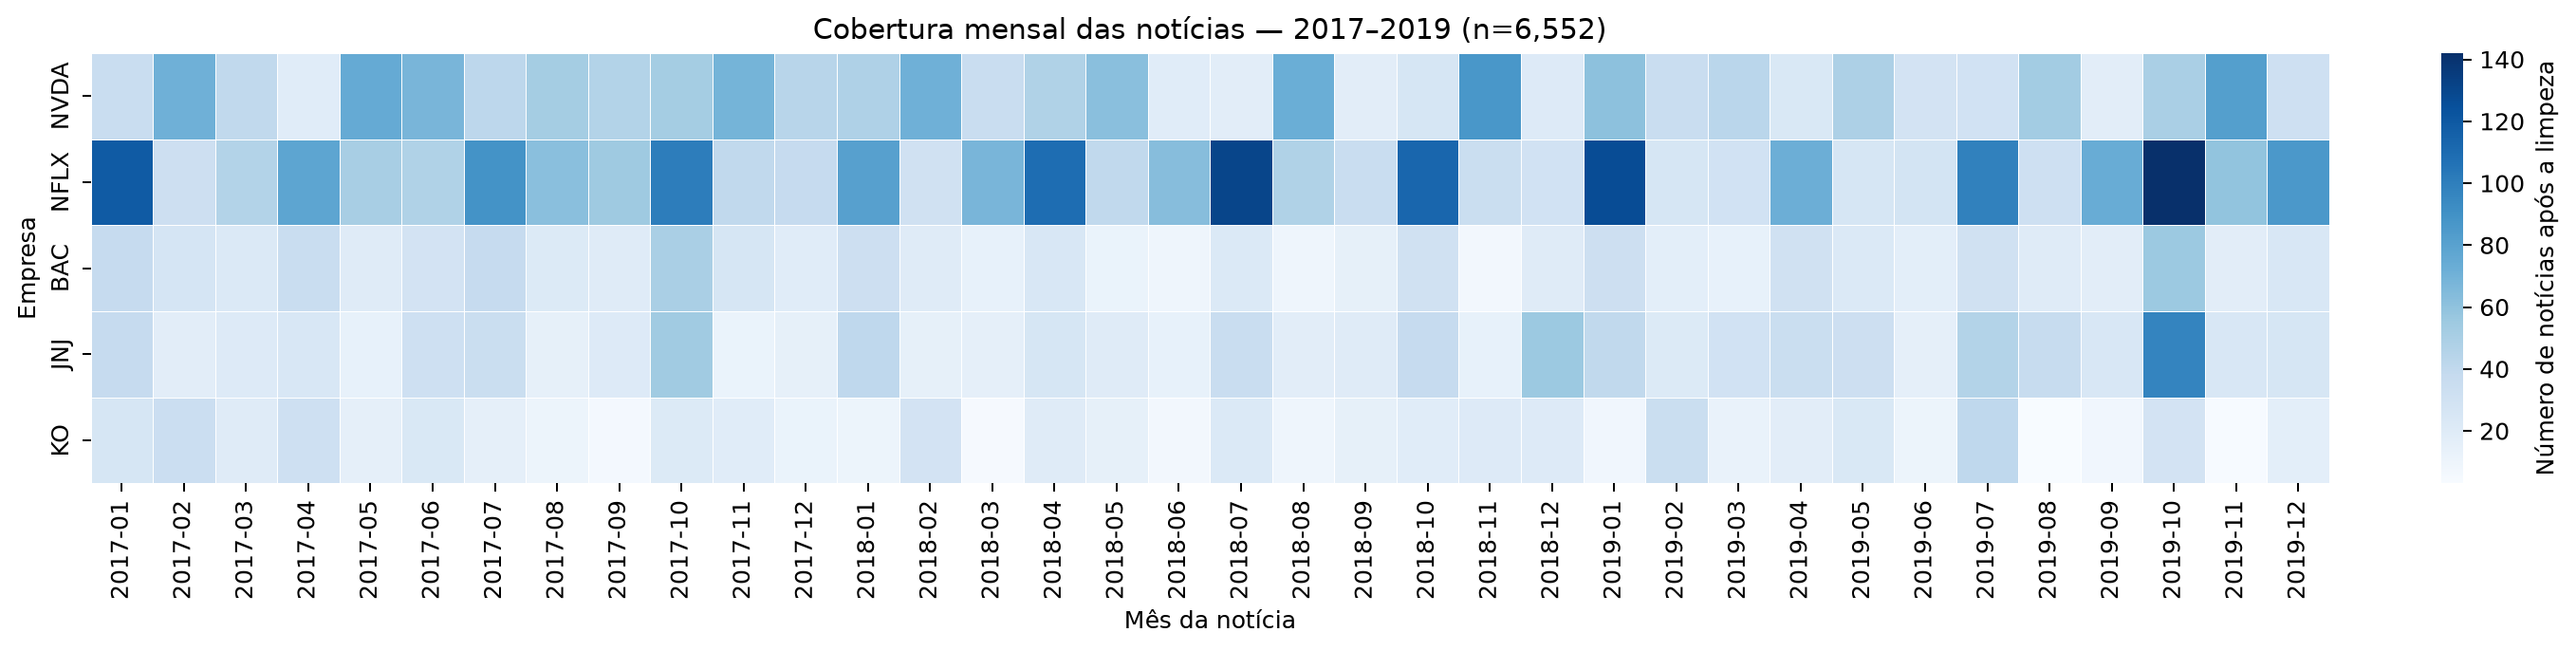

In [3]:
display(Image(filename=str(figura), alt='Mapa de calor de cinco empresas por mês: NFLX tem a maior cobertura total e KO a menor. A tabela 1 apresenta os totais anuais em texto.'))

**Resultado e interpretação.** NFLX apresenta a maior cobertura em todos os anos, totalizando 2.344 associações, e KO a menor, com 644. NVDA reúne 1.647, JNJ 1.046 e BAC 871. A evolução também difere: a contagem anual de NFLX cresce de 759 para 801, enquanto a de NVDA diminui de 614 para 507. O mapa de calor permite observar a variação mensal dentro de cada série. Portanto, a base oferece quantidades diferentes de informação para as comparações entre empresas e períodos, sustentando a descrição de cobertura desigual prevista em H1.

**Limites da resposta.** Contagens refletem a cobertura do corpus e seus critérios editoriais, não a quantidade total de notícias do mercado. Uma mesma manchete pode contribuir para empresas distintas. A intensidade da cor representa quantidade de registros, não sentimento nem magnitude de retorno. Esses resultados não explicam a origem das diferenças de cobertura.

**Atualização de 16/10.** O notebook 04 reproduziu a contagem das 6.552 associações e o mapa mensal, acrescentando barras com os totais. A versão com os dois painéis está em [cobertura mensal e totais](../figures/analise_visual/q1_cobertura.png). O resultado permanece consistente com H1; cobertura é uma característica do corpus, sem explicar o comportamento dos preços.

## 5. Pergunta 2 — Quais empresas apresentam maiores proporções de manchetes positivas, neutras e negativas?

**Preparação realizada.** O notebook 02 já classificou as manchetes e contou as classes dentro de cada empresa. A tabela 2 recupera essas frequências absolutas. A unidade continua sendo a associação manchete–empresa, sem filtro de elegibilidade dos retornos.

**Tabela 2. Contagens de classes automáticas por empresa, 2017–2019.** Os totais são diferentes entre empresas e não devem ser comparados como se fossem proporções.

In [4]:
display(classes.rename(columns={'positivo': 'Positivo', 'neutro': 'Neutro',
                                'negativo': 'Negativo', 'empate': 'Empate',
                                'total': 'Total'}).rename_axis('Empresa'))

,Positivo,Neutro,Negativo,Empate,Total
Empresa,,,,,
BAC,162,524,185,0,871
JNJ,306,516,224,0,1046
KO,138,398,108,0,644
NFLX,556,1359,429,0,2344
NVDA,451,801,395,0,1647


**Resultado e interpretação.** Neutro é a classe mais frequente nas cinco empresas, mas não supera 50% em JNJ e NVDA. KO tem a maior proporção neutra (61,8%), JNJ a maior positiva (29,3%) e NVDA a maior negativa (24,0%). BAC apresenta 18,6% de positivas e 21,2% de negativas. Comparar proporções dentro de cada empresa evita confundir cobertura com composição do sentimento. Não houve empate nas classes por manchete.

**Transformação.** Dividimos as contagens da tabela 2 pelo total da respectiva empresa. A figura usa barras de 100% com o denominador indicado; abrange todas as associações de 2017–2019, sem o filtro de elegibilidade dos retornos.


![Barras de 100% por empresa; neutro é a maior classe nas cinco séries.](../figures/analise_visual/q2_composicao.png)

**Figura 2. Composição do sentimento por empresa.** n = 6.552 associações; percentuais calculados dentro de cada empresa. Fonte: Kaggle e FinBERT, processamento do grupo.

**Limitação.** O modelo classifica o texto inteiro e pode transferir o tom de uma manchete sobre várias empresas a todos os tickers vinculados. A revisão dirigida de 50 casos não estima a acurácia geral, e as classes não são uma verdade observada sem erro.

## 6. Pergunta 3 — Como o sentimento agregado varia ao longo do tempo e quais períodos concentram extremos?

**Transformação e leitura.** A média dos escores e a contagem foram calculadas para cada empresa/data civil. O gráfico apresenta os 2.569 grupos em painéis separados, com a mesma escala de −1 a 1 e tamanho de ponto proporcional à contagem pela regra indicada no eixo. Dias sem notícias ficam sem ponto. Os círculos destacam o mínimo e o máximo de cada empresa; empates seriam resolvidos pela data mais antiga.


![Escores diários em cinco painéis, com mínimo e máximo destacados; os dez extremos têm n igual a um.](../figures/analise_visual/q3_evolucao.png)

**Figura 3. Evolução diária do sentimento, 2017–2019.** A unidade é empresa/data civil, incluindo fins de semana com notícias. Fonte: Kaggle e FinBERT, processamento do grupo.

**Resultado.** Há oscilações de ambos os sinais ao longo do recorte, com coberturas distintas. Os dez extremos selecionados são todos sustentados por **uma única manchete**; assim, descrevem classificações pontuais, sem demonstrar um período de tom persistente.

**Tabela 3. Extremos diários identificados de modo determinístico.**

| Empresa | Extremo | Data | Escore | n |
| --- | --- | --- | --- | --- |
| BAC | mínimo | 2019-08-09 | -0.964 | 1 |
| BAC | máximo | 2019-01-30 | 0.935 | 1 |
| JNJ | mínimo | 2018-02-05 | -0.961 | 1 |
| JNJ | máximo | 2018-10-24 | 0.939 | 1 |
| KO | mínimo | 2019-10-02 | -0.966 | 1 |
| KO | máximo | 2019-04-03 | 0.941 | 1 |
| NFLX | mínimo | 2018-05-10 | -0.962 | 1 |
| NFLX | máximo | 2019-06-17 | 0.932 | 1 |
| NVDA | mínimo | 2019-03-06 | -0.966 | 1 |
| NVDA | máximo | 2019-09-25 | 0.934 | 1 |

**Conferência dos textos.** Em BAC, o mínimo relata queda de várias blue chips junto ao mercado; o máximo menciona uma previsão de PACCAR sobre caminhões, não BAC no título. Essa associação ticker/manchete merece revisão, mas foi preservada. Em JNJ, o mínimo relata queda da ação e discussão de um julgamento; o máximo menciona resultados clínicos de Stelara. Em KO, o mínimo relata queda junto ao mercado e receio de recessão; o máximo descreve crescimento de vendas. Em NFLX, o mínimo descreve queda recente sem notícia que a justificasse; o máximo relata alta e tendências de assinantes. Em NVDA, o mínimo menciona queda nas vendas globais de chips; o máximo descreve alta sem notícia específica e valorização nos três meses anteriores. Os textos e identificadores estão em `data/processed/manchetes_extremos_analise.csv` no pacote local e nas saídas do notebook 04.

**Limitação.** Essa leitura aponta exemplos de retrospectivas e de associação indireta a tickers. Não valida o tom específico de cada empresa nem explica movimentos futuros. Nenhum exemplo foi excluído para favorecer o resultado. Revisar também extremos apoiados em várias manchetes é uma melhoria prevista; esse recorte descritivo não comprova H2 ou H3.

## 7. Pergunta 4 — Como se distribuem os retornos do pregão seguinte a dias com sentimento positivo, neutro ou negativo?

**Transformação.** Utilizamos 2.387 pares empresa/pregão com notícias e janela completa. A classe resulta da maior probabilidade média das manchetes reunidas no mesmo pregão. Não repetimos retornos por manchete. As caixas apresentam Q1, mediana e Q3; os bigodes alcançam observações dentro de 1,5 vezes o intervalo interquartil, mantendo os demais pontos visíveis.


![Boxplots com grande sobreposição entre classes, escalas comuns e todos os extremos preservados.](../figures/analise_visual/q4_retornos_classes.png)

**Figura 4. Distribuições dos retornos por classe e empresa.** Retorno em porcentagem; n aparece sob cada caixa. Fonte: painel integrado do grupo.

**Tabela 4. Mediana do retorno e número de pregões por classe.**

| Empresa | Negativo | Neutro | Positivo |
| --- | --- | --- | --- |
| BAC | 0.000% (n=88) | 0.000% (n=289) | -0.061% (n=61) |
| JNJ | 0.092% (n=70) | 0.000% (n=245) | 0.163% (n=131) |
| KO | 0.095% (n=36) | 0.090% (n=251) | 0.087% (n=47) |
| NFLX | -0.498% (n=78) | 0.148% (n=447) | 0.015% (n=102) |
| NVDA | 0.382% (n=119) | 0.200% (n=289) | -0.173% (n=134) |

**Resultado e interpretação.** As distribuições se sobrepõem e não exibem uma ordenação positiva > neutra > negativa comum às cinco empresas. Em NFLX, a mediana é −0,498% na classe negativa e +0,015% na positiva; em NVDA, a relação se inverte: +0,382% e −0,173%, respectivamente. Em JNJ, as medianas de negativo e positivo são ambas positivas. A dispersão dentro das classes é relevante, especialmente em NFLX e NVDA. Assim, o rótulo de sentimento não separa os retornos de forma uniforme neste recorte.

**Limitação.** Tamanhos diferentes, casos extremos, notícias retrospectivas e ausência de horários limitam a leitura. Em JNJ/negativo, por exemplo, a média é negativa (−0,244%), embora a mediana seja positiva (+0,092%), mostrando por que o centro depende da medida. Diferenças observadas não demonstram significância estatística, previsibilidade fora da amostra ou efeito causal.

## 8. Pergunta 5 — Dias com mais notícias ou sentimento mais intenso são seguidos por maiores oscilações, medidas pelo retorno absoluto?

**Transformação.** Nos mesmos 2.387 pares, comparamos contagem de notícias e módulo do escore agregado com o módulo do retorno. As dispersões preservam todos os pontos e compartilham escalas. Spearman é calculado como correlação dos postos médios, tratando empates; serve apenas como resumo descritivo.


![Dispersões de contagem de notícias versus retorno absoluto, por empresa.](../figures/analise_visual/q5_quantidade.png)

**Figura 5a. Quantidade de notícias e retorno absoluto.** A contagem se refere à janela mapeada para o pregão, que pode receber mais de uma data civil.


![Dispersões de intensidade versus retorno absoluto; coeficientes próximos de zero.](../figures/analise_visual/q5_intensidade.png)

**Figura 5b. Intensidade líquida do sentimento e retorno absoluto.** Fonte das duas figuras: painel integrado; n = 2.387 pares elegíveis. Os títulos mostram n e Spearman.

**Tabela 5. Associações monotônicas descritivas no período completo.**

| Empresa | n | ρ quantidade × absoluto | ρ intensidade × absoluto |
| --- | --- | --- | --- |
| BAC | 438 | 0.033 | 0.011 |
| JNJ | 446 | 0.030 | -0.010 |
| KO | 334 | 0.161 | 0.055 |
| NFLX | 627 | 0.057 | 0.030 |
| NVDA | 542 | 0.125 | 0.016 |

**Resultado e interpretação.** Quantidade e retorno absoluto têm coeficientes positivos de 0,030 a 0,161, maiores em KO (0,161) e NVDA (0,125), ainda com grande dispersão. Para intensidade, os coeficientes variam de −0,010 a +0,055, próximos de zero. **H2 não recebe apoio descritivo claro nesta operacionalização:** maior intensidade líquida não acompanha uma elevação consistente da magnitude posterior.

**Limitação.** O módulo do escore médio permite compensação de manchetes opostas e não equivale à média das intensidades individuais. Correlação próxima de zero não exclui relações não monotônicas. Retorno absoluto mede oscilação diária, não volatilidade formal. Cobertura pode ser maior justamente em contextos turbulentos, sem identificar direção causal.

## 9. Pergunta 6 — As associações entre sentimento e retorno apresentam direção e intensidade semelhantes entre empresas e anos?

**Transformação.** Separação pelo ano do pregão de resposta, preservando o filtro principal. Cada célula do mapa informa Spearman e n; a cor usa uma escala fixa de −1 a 1. As dispersões mostram os pontos subjacentes por empresa.


![Mapa de correlações pequenas, com mudanças de sinal por empresa e ano e tamanhos amostrais anotados.](../figures/analise_visual/q6_correlacoes.png)

**Figura 6a. Escore agregado versus retorno por empresa/ano e no período completo.** Fonte: painel integrado; n anual entre 99 e 215.


![Dispersões de escore e retorno por empresa, com escalas comuns e concentração sem inclinação clara.](../figures/analise_visual/q6_dispersoes.png)

**Figura 6b. Dispersões de apoio, 2017–2019.** n = 2.387 pares, distribuídos entre cinco empresas; não se estima uma única correlação combinando empresas.

**Resultado e interpretação.** No período completo, ρ varia de −0,041 (NVDA) a +0,058 (NFLX), próximo de zero nas cinco empresas. Entre os 15 grupos anuais, vai de −0,153 (NVDA/2019) a +0,123 (JNJ/2019). NFLX passa de +0,121 em 2018 a −0,040 em 2019; JNJ passa de −0,074 a +0,123. H3 encontra variação descritiva de sinal e magnitude, mas os coeficientes pequenos **não demonstram uma diferença estrutural** entre anos ou empresas. A resposta inicial é de associações fracas e instáveis neste recorte.

**Limitação.** Não foram realizados testes de diferença entre coeficientes, intervalos de confiança ou validação temporal. Dependência temporal, manchetes compartilhadas e grupos de tamanhos diferentes impedem interpretar as células como estimativas independentes ou confirmar uma relação generalizável.

## 10. Pergunta 7 — Os padrões permanecem ao excluir retrospectivas e exigir pelo menos três notícias?

**Comparação inicial executada.** Nesta etapa testamos somente **n_noticias ≥ 3 por empresa/pregão**, sobre a amostra principal. O limite estava previsto antes das comparações. Os escores dos pregões retidos não mudam, pois nenhuma de suas manchetes foi retirada. Foram repetidos os três coeficientes e os resumos de retorno por classe; as tabelas completas estão em `docs/analise_visual/q7_*.csv`.


![Comparação dos três coeficientes entre amostra principal e mínimo de três notícias; contagens de antes e depois por empresa.](../figures/analise_visual/q7_minimo_tres.png)

**Figura 7. Primeira sensibilidade a um mínimo de notícias por pregão.** Fonte: painel integrado. 2.387 pares na principal e 783 no subconjunto; as amostras são sobrepostas.

**Tabela 6. Composição após o filtro.**

| Empresa | Principal | Mínimo 3 | Retenção (%) |
| --- | --- | --- | --- |
| BAC | 438 | 88 | 20.1 |
| JNJ | 446 | 123 | 27.6 |
| KO | 334 | 58 | 17.4 |
| NFLX | 627 | 307 | 49.0 |
| NVDA | 542 | 207 | 38.2 |

**Resultado e interpretação.** Restam 783 pares (32,8% da amostra principal). A retenção vai de 17,4% em KO a 49,0% em NFLX, alterando a composição. Em KO, escore × retorno passa de +0,002 a −0,196 (n de 334 para 58); em JNJ, de +0,031 a −0,095. Em NFLX, fica próximo: +0,058 e +0,051. Para intensidade × retorno absoluto, NFLX passa de +0,030 a −0,088 e NVDA de +0,016 a −0,122. Os resultados não mostram um padrão de sinal estável em todas as empresas. O filtro também restringe a amplitude de contagens, afetando a comparação quantidade × retorno absoluto.

**O que permanece pendente.** A pergunta 7 está parcialmente respondida. Não excluímos retrospectivas nem testamos os filtros combinados. O planejamento define retrospectiva como manchete que relata movimento de preço já ocorrido; falta operacionalizar e revisar os casos, com critérios de ambiguidade. A marcação deve ser feita sem consultar o efeito da exclusão nos retornos. Depois será necessário reagrupar as manchetes remanescentes e reaplicar o mínimo de três sobre a nova contagem. Retenção desigual e amostra menor também podem explicar mudanças; não declaramos robustez completa.

## 11. Conclusões provisórias, recomendações e limitações

A análise visual mantém H1: a cobertura é desigual entre empresas e meses. Neutro é a classe mais frequente nas cinco empresas, sem representar maioria absoluta em todas. Os extremos diários de escore selecionados dependem de uma única manchete cada, e sua leitura revelou retrospectivas e um título sobre outra empresa associado a BAC. Isso limita o significado econômico do escore sem invalidar o registro do que o modelo calculou.

As distribuições de retorno por classe apresentam sobreposição e não seguem uma ordem uniforme. A intensidade líquida não apresenta associação monotônica clara com o retorno absoluto, oferecendo pouco apoio descritivo a H2 nesta definição. Para H3, os coeficientes escore/retorno mudam de sinal entre empresas e anos, mas permanecem pequenos; não se demonstrou diferença estrutural. O mínimo de três notícias altera a composição e alguns sinais. A conclusão provisória é de relações fracas e sensíveis à seleção, sem alegação de robustez completa.

As limitações incluem uma única fonte de manchetes, cinco empresas, três anos, ausência de horário confiável, classificação do texto inteiro, possível associação indireta de ticker, dependência temporal e notícias compartilhadas. A revisão humana dirigida não estima acurácia populacional. Não houve controle por fatores de mercado, inferência causal, testes de significância ou validação fora da amostra. Retorno absoluto é magnitude diária, e intensidade líquida permite compensação de tons.

**Melhorias prioritárias.** Revisar textos retrospectivos e casos ambíguos sem consultar o resultado financeiro; reagrupar após exclusões e aplicar os filtros separados e combinados; revisar extremos com maior suporte de manchetes; examinar a composição por empresa/ano; e realizar a reprodução integral por outro integrante. Essas pendências orientam a revisão de 24–26/10 e as etapas seguintes. O trabalho permanece em desenvolvimento e não oferece recomendação de investimento.

## 12. Reprodutibilidade e material de apoio

**Leitura e reconstrução deste artigo.** Abra este notebook no GitHub para consultar os resultados salvos ou execute suas quatro células de código em ordem no Jupyter. Elas leem apenas arquivos versionados: resumos transcritos das saídas anteriores, registros de execução e a figura de cobertura. As novas figuras e tabelas também estão versionadas em `figures/analise_visual` e `docs/analise_visual`. O arquivo [resultados_registrados.json](../docs/resultados_registrados.json) identifica o commit de origem, as células e as assinaturas digitais das saídas. Ele é um registro da versão de referência e não se atualiza automaticamente quando outros notebooks são executados.

**Reprodução do processamento.** Execute os notebooks 01, 02, 03 e 04 nessa ordem, conforme o [README](../README.md). Eles contêm o código de limpeza, transformação, classificação, geração da figura e integração, com explicações junto às células. O CSV original, os snapshots de preços, as bases completas e os pesos do modelo não estão versionados. Uma reprodução integral exige essas entradas; para repetir exatamente os resultados datados, é necessário obter os snapshots do grupo e conferir os hashes. A reconstrução das tabelas deste artigo não substitui esse teste.

| Material | Função |
| --- | --- |
| [Notebook 01](01_preparacao_inicial.ipynb) | Preparação, auditorias, cobertura e geração da figura 1 |
| [Notebook 02](02_sentimento_finbert.ipynb) | Classificação, agregação por data civil e revisão humana |
| [Notebook 03](03_integracao_retornos.ipynb) | Calendário, alinhamento, retornos e painel elegível |
| [Notebook 04](04_analise_visual.ipynb) | Nove gráficos, onze tabelas e comparação inicial de robustez |
| [Relatório FinBERT](../docs/finbert.md) | Matriz da revisão, exemplos e limites da classificação |
| [Relatório de integração](../docs/integracao.md) | Regras, bordas e auditoria do calendário |
| [Adequação ao enunciado](../docs/adequacao_artigo.md) | Correspondência entre a estrutura e as exigências acadêmicas |

Os registros datados descrevem o estado ao término de cada etapa. Assim, a indicação de integração pendente no registro do FinBERT é histórica; a execução de integração posterior está documentada em seu próprio registro. A reprodução integral por outro integrante e a incorporação do retorno do professor continuam a cargo do grupo.

A etapa 04 executou suas 12 células em sequência sobre os snapshots do pacote. Não reexecutou inferência nem coleta de preços; hashes confirmam preservação das três entradas. O [manifesto visual](../docs/analise_visual/manifesto.json) distingue esta execução dos registros anteriores.

## Referências

[1] AENLLE, Miguel. *Daily Financial News for 6000+ Stocks*. Kaggle. [Base de notícias](https://www.kaggle.com/datasets/miguelaenlle/massive-stock-news-analysis-db-for-nlpbacktests). Arquivo utilizado: `raw_analyst_ratings.csv`.

[2] YAHOO FINANCE; YFINANCE. *Cotações históricas e documentação de yfinance.download*. [Documentação de coleta](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html). Snapshot utilizado: 09/10/2026; parâmetros e hashes no [registro de integração](../docs/execucoes/integracao_2026-10-15.json).

[3] PROSUSAI. *FinBERT*. Hugging Face. [Modelo e documentação](https://huggingface.co/ProsusAI/finbert); [revisão utilizada](https://huggingface.co/ProsusAI/finbert/tree/4556d13015211d73dccd3fdd39d39232506f3e43).

[4] ARACI, Dogu. *FinBERT: Financial Sentiment Analysis with Pre-trained Language Models*. 2019. [arXiv:1908.10063](https://arxiv.org/abs/1908.10063).

[5] EXCHANGE_CALENDARS; ICE/NYSE. Calendário XNYS e comunicados históricos. [Biblioteca](https://github.com/gerrymanoim/exchange_calendars); [calendário 2017–2019](https://ir.theice.com/press/news-details/2016/NYSE-Group-announces-2018-and-2019-holiday-and-early-closings-calendar/default.aspx); [calendário 2018–2020](https://ir.theice.com/press/news-details/2017/NYSE-Group-Announces-2018-2019-and-2020-Holiday-and-Early-Closings-Calendar/default.aspx); [fechamento extraordinário de 05/12/2018](https://ir.theice.com/press/news-details/2018/New-York-Stock-Exchange-to-Honor-President-George-H-W-Bush/default.aspx).

[6] RULFF, João. *Projeto Final — Análise Exploratória de Dados e Visualização*. FGV EMAp, 2026.2, p. 1–2. Enunciado fornecido à turma, arquivo `AED20262_projeto.pdf`. A proposta e o cronograma do grupo são documentos internos descritos no [índice documental](../docs/README.md).

[7] PANDAS; MATPLOTLIB. Documentação de [correlação](https://pandas.pydata.org/docs/reference/api/pandas.Series.corr.html), [postos](https://pandas.pydata.org/docs/reference/api/pandas.Series.rank.html) e [boxplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.boxplot.html). Consultada em 16/10/2026.